#### Health Insurance Fraud Risk Assessment

#### Part 1: Objective 

#### This analysis evaluates whether a selected provider exhibits billing behaviour that significantly deviates from peers within the same specialty. The goal is to identify statistical signals that may indicate elevated fraud or overbilling risk.

In [185]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, recall_score, precision_score

In [186]:
encounters = pd.read_csv("encounters.csv")
claims = pd.read_csv("claims.csv")
organizations = pd.read_csv("organizations.csv")
patients = pd.read_csv("patients.csv")
providers = pd.read_csv("providers.csv")

### Claim Cost Deviation Analysis

#### Purpose 

To determine whether the target provider's average claim cost is significantly higher than the average cost among peer providers within the same specialty.

#### Key idea

We compare the target provider against a peer benchmark defined as: all general practice providers excluding the target provider

### Provider Identification and Context

The target provider is first retrieved to confirm their identity, speciality classification, and organizational affiliation. 

Verifying the provider's attributes ensures:
- Correct specialty-based peer benchmarking
- Accurate group inclusion for statistical comparison 
- Contextual understanding of organizational alignment

The information below establishes the provider profile used for subsequent analysis. 

In [187]:
gp_provider = providers[providers['ID'] == "bb49afa2-3d8a-306c-a06e-a1715dd71af8"]
gp_provider

,ID,NAME,SPECIALITY,GENDER,ORGANIZATION
0,bb49afa2-3d8a-306c-a06e-a1715dd71af8,Provider_0000,GENERAL PRACTICE,F,226098a2-6a40-3588-b5bb-db56c3a30a04


### Benchmark Construction

Using general practice encounters: 
- The target provider claim costs are treated as the sample distribution of interest
- The peer provider claim costs (excluding the target) are used to compute a benchmark mean

This benchmark mean is used as the reference value in the hypothesis test

In [188]:
gp_provider = providers[providers['SPECIALITY'] == 'GENERAL PRACTICE']['ID'].unique()
gp_encounters = encounters[encounters['PROVIDER'].isin(gp_provider)]

avg_claim_gp = gp_encounters[gp_encounters['PROVIDER'] == "bb49afa2-3d8a-306c-a06e-a1715dd71af8"]['TOTAL_CLAIM_COST'].mean()
avg_claim_op = gp_encounters[gp_encounters['PROVIDER'] != "bb49afa2-3d8a-306c-a06e-a1715dd71af8"]['TOTAL_CLAIM_COST'].mean()

print(f"Average claim for general practice ${avg_claim_gp}")
print(f"Average claim for other providers ${avg_claim_op}")

Average claim for general practice $508.4995833333333
Average claim for other providers $497.2091693548387


### Provider Information Integration

To enable provider-level analysis within each encounter record, the encounters dataset is merged with the providers dataset. 

This step appends provider attributes (e.g name, specialty, gender, organization) to each encounter entry.

The enriched dataset allows:
- Specialty-based filtering
- Provider-level claim aggregation
- Peer group benchmarking

In [189]:
df = pd.merge(encounters, providers, left_on='PROVIDER', right_on='ID', suffixes=(' ', '_y'))
df = df.loc[:, ~df.columns.str.endswith('_y')]
df.columns = df.columns.str.rstrip('_x')
df.head()

,ID,PATIENT,PROVIDER,ORGANIZATION,ENCOUNTERCLASS,TOTAL_CLAIM_COST,NAME,SPECIALITY,GENDER
0,42db7c89-155a-4822-a83b-108297566c6d,216ef7c6-5d75-4ed2-9e88-7590f5a62e8d,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,inpatient,666.17,Provider_0000,GENERAL PRACTICE,F
1,4582737d-9c66-4231-8744-25e9a37e8f32,2f520255-a75c-4b2d-b859-635c1e7afe0b,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,outpatient,461.31,Provider_0000,GENERAL PRACTICE,F
2,21340ce9-082a-4f62-a53a-2533c43d355b,f3c98a41-b8d8-498b-b2e3-231cd8ae8916,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,508.69,Provider_0000,GENERAL PRACTICE,F
3,11c9005f-d83b-4cc5-be3b-0134603f1efb,16f9eb9f-f276-404e-a785-ef64af0b29e8,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,544.28,Provider_0000,GENERAL PRACTICE,F
4,62c82b0c-7c53-4501-b99b-15f96d6df6f1,66062c99-6bf7-4226-92e2-726e799e2588,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,430.62,Provider_0000,GENERAL PRACTICE,F


#### Overall General Practice Benchmark

Before isolating the target provider, we compute the overall average total claim cost across all providers within the General Practice specialty. 

This value serves as a high-level benchmark for contextual comparison against the target provider's claim behaviour. 

In [190]:
avg_total_claim_gp = df[df['SPECIALITY'] == 'GENERAL PRACTICE']['TOTAL_CLAIM_COST'].mean()
avg_total_claim_gp

498.2053823529412

### Hypotheses

A one-sided one-sample t-test is conducted to evaluate whether the target provider's average total claim cost exceeds the peer benchmark mean. 

- Null Hypothesis: The target provider's mean total claim cost is less than or equal to the peer group mean.
- Alternative Hypothesis: The target provider's mean total claim cost is greater than the peer group mean. 

Significance level: 0.05

In [191]:
provider_id = "bb49afa2-3d8a-306c-a06e-a1715dd71af8"
provider_info = providers.loc[providers['ID'] == provider_id]
gp_providers_ids = providers[providers['SPECIALITY'] == 'GENERAL PRACTICE']['ID']
specific_provider_claims = encounters[encounters['PROVIDER'] == provider_id]['TOTAL_CLAIM_COST']

other_gp_providers_claims = encounters[encounters['PROVIDER'].isin(gp_providers_ids) & (encounters['PROVIDER'] != provider_id)]['TOTAL_CLAIM_COST']

average_claim_cost_for_others = other_gp_providers_claims.mean()

specific_provider_claims.describe(), average_claim_cost_for_others

from scipy.stats import ttest_1samp

t_stat, p_value = ttest_1samp(specific_provider_claims, popmean=average_claim_cost_for_others, alternative='greater')

t_stat, p_value

(1.2996599738676649, 0.09811478012660584)

### Interpretation (95% Confidence Level)

The one-sample t-test produced:
- t-statistic = 1.30
- p-value = 0.099

Since the p-value exceeds the significance level of 0.05, we fail to reject the null hypothesis. 

There is insufficient statistical evidence at the 95% confidence level to conclude that the target provider's mean total claim cost is greater than the peer benchmark mean. 

Although the provider's average appears numerically higher, the observed difference is not statistically significant under the chosen threshold. 

### Claim Cost Comparison between Organizations
- There are two organizations with similar profiles (types of patients seen, location etc.) for which we want to test whether the total claim costs between them are indeed similar as well. 
- The IDs of the two organizations are "226098a2-6a40-3588-b5bb-db56c3a30a04" and "108ccece-277a-396f-8bf2-1527f74458eb"

In [192]:
org1_id = "226098a2-6a40-3588-b5bb-db56c3a30a04"
org2_id = "108ccece-277a-396f-8bf2-1527f74458eb"

In [193]:
org1_claim_costs = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST']
org2_claim_costs = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST']

org1_avg_costs = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST'].mean()
org2_avg_costs = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST'].mean()

#### Claim Cost Extraction

Total claim costs are retrieved separately for each organization to construct two independent samples for comparison

In [194]:
org_ids = [org1_id, org2_id]
org_details_df = organizations[organizations['ID'].isin(org_ids)]

org_details_df

,ID,NAME,CITY,STATE
0,226098a2-6a40-3588-b5bb-db56c3a30a04,AVON PCP GROUP A,AVON,MA
1,108ccece-277a-396f-8bf2-1527f74458eb,WATERTOWN PCP GROUP B,WATERTOWN,MA


#### Descriptive Comparison

The mean total claim cost is computed for each organization to provide an initial comparison prior to hypothesis testing

In [195]:
org1_sum_costs = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST'].sum()
org2_sum_costs = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST'].sum()

print(f' Total claim costs for organization 1 is ${org1_sum_costs}')
print(f' Total claim costs for organization 2 is ${org2_sum_costs}')

 Total claim costs for organization 1 is $120272.9
 Total claim costs for organization 2 is $59387.11


#### Hypotheses (Two-tailed test)

- **H₀:** The mean total claim cost for Organization 1 equals that of Organization 2.
- **H₁:** The mean total claim cost for Organization 1 differs from that of Organization 2.

Significance level: α = 0.05

In [196]:
org1_id = "226098a2-6a40-3588-b5bb-db56c3a30a04"
org2_id = "108ccece-277a-396f-8bf2-1527f74458eb"

org1_data = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST']
org2_data = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST']

# Check the size of the datasets for both organizations
org1_size = org1_data.size
org2_size = org2_data.size

from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(org1_data, org2_data, equal_var=True)

t_stat, p_value

(0.3974923265156138, 0.6912406773266538)

#### Interpretation (95% Confidence Level)

The two-sample independent t-test resulted in a t-statistic of approximately 0.398 and a p-value of approximately 0.692.
The p-value indicates the probability of observing the test results under the null hypothesis, which in this context is that there is no difference in the mean total claim costs between the two organizations. A p-value of 0.692 is much higher than the common alpha level of 0.05, suggesting that we do not have enough evidence to reject the null hypothesis. Therefore, based on this analysis, it appears that there is no statistically significant difference in the mean total claim costs between the two organizations.

- At a 95% confidence level, the p-value is higher than the significance level of 0.05
- Therefore, we do not reject the null hypothesis, and conclude that the average total claim costs between the two organizations are similar

#### Multi-Organization Claim Cost Analysis

This section evaluates whether average total claim costs differ significantly across primary care practices (PCPs) located within selected cities.

The analysis focuses on organizations operating in the cities of AVON and WATERTOWN, with the goal of determining whether any organization exhibits a statistically distinct mean claim cost compared to others within this regional cohort. 

#### Organizational Claim Cost Extraction

Encounter-level data is enriched with organizational attributes (name and city) to enable grouping of total claim costs at the organization level.

This integratin allows construction of independent claim-cost samples for each organization within the selected cities. 

In [197]:
merge_data = pd.merge(encounters,
                      organizations[['ID', 'NAME', 'CITY']],
                      left_on='ORGANIZATION',
                      right_on='ID',
                      how='left').drop(columns=['ID_y']).rename(columns={'ID_x': 'ID', 'NAME': 'ORGANIZATION_NAME', 'CITY': 'ORGANIZATION_CITY'})

merge_data

,ID,PATIENT,PROVIDER,ORGANIZATION,ENCOUNTERCLASS,TOTAL_CLAIM_COST,ORGANIZATION_NAME,ORGANIZATION_CITY
0,42db7c89-155a-4822-a83b-108297566c6d,216ef7c6-5d75-4ed2-9e88-7590f5a62e8d,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,inpatient,666.17,AVON PCP GROUP A,AVON
1,4582737d-9c66-4231-8744-25e9a37e8f32,2f520255-a75c-4b2d-b859-635c1e7afe0b,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,outpatient,461.31,AVON PCP GROUP A,AVON
2,21340ce9-082a-4f62-a53a-2533c43d355b,f3c98a41-b8d8-498b-b2e3-231cd8ae8916,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,508.69,AVON PCP GROUP A,AVON
3,11c9005f-d83b-4cc5-be3b-0134603f1efb,16f9eb9f-f276-404e-a785-ef64af0b29e8,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,544.28,AVON PCP GROUP A,AVON
4,62c82b0c-7c53-4501-b99b-15f96d6df6f1,66062c99-6bf7-4226-92e2-726e799e2588,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,430.62,AVON PCP GROUP A,AVON
...,...,...,...,...,...,...,...,...
5095,3e4d48b8-e022-4b5b-9fa3-0f92c87e7138,ca3ae481-0db6-4f26-846b-71e7a0a2e6d2,0df1d27c-9bcc-4030-b7ea-f44284e5a379,d88dcaf5-f283-4158-a4d5-3df46261794e,inpatient,485.20,ORG 2250 PCP,AVON
5096,3dc27814-13c3-4040-97a2-566db22122ef,5983ddfc-4740-456e-ae68-6f6972103ec8,69a805c6-9d0a-496a-b451-1ca8b89cb225,981a09bc-b549-458f-814c-a2ade0adf60f,ambulatory,513.59,ORG 3066,SOMERVILLE
5097,b764d2dd-b013-4d5b-9d84-05baa8af70a5,8e181b8f-1abb-410d-ac92-80a3414bfbe6,b410c143-dba9-429e-acbe-2b921af22c3e,e5afe40c-91ef-42d7-a25c-41ef5f41663a,inpatient,569.59,ORG 3741,LOWELL
5098,ccc2c153-9644-4e39-bc59-54425b0800ef,4b5533b5-1a7e-417d-a8c0-63aa77bf4d0f,ffea9728-5110-434a-8608-6c5bc8529450,3a00bb32-3f67-44dd-86c2-aa8cb715438b,ambulatory,323.56,ORG 0321,AVON


#### Regional Filtering
The dataset is filtered to include only organizations operating in AVON and WATERTOWN. This ensures that comparisons are made within a defined geographic context. 

In [198]:
filtered_data = merge_data[(merge_data['ORGANIZATION_NAME'].str.contains("PCP")) & (merge_data['ORGANIZATION_CITY'].isin(["AVON", "WATERTOWN"]))]
filtered_data

,ID,PATIENT,PROVIDER,ORGANIZATION,ENCOUNTERCLASS,TOTAL_CLAIM_COST,ORGANIZATION_NAME,ORGANIZATION_CITY
0,42db7c89-155a-4822-a83b-108297566c6d,216ef7c6-5d75-4ed2-9e88-7590f5a62e8d,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,inpatient,666.17,AVON PCP GROUP A,AVON
1,4582737d-9c66-4231-8744-25e9a37e8f32,2f520255-a75c-4b2d-b859-635c1e7afe0b,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,outpatient,461.31,AVON PCP GROUP A,AVON
2,21340ce9-082a-4f62-a53a-2533c43d355b,f3c98a41-b8d8-498b-b2e3-231cd8ae8916,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,508.69,AVON PCP GROUP A,AVON
3,11c9005f-d83b-4cc5-be3b-0134603f1efb,16f9eb9f-f276-404e-a785-ef64af0b29e8,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,544.28,AVON PCP GROUP A,AVON
4,62c82b0c-7c53-4501-b99b-15f96d6df6f1,66062c99-6bf7-4226-92e2-726e799e2588,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,430.62,AVON PCP GROUP A,AVON
...,...,...,...,...,...,...,...,...
5065,89046686-c30c-46fe-9be9-8cc38585da5c,f343b29b-07c6-4bf0-9084-7c31c95a1006,76c4e182-3240-413f-b71a-e5dcbeeaca76,71b4dddb-7fa6-4a4e-828d-e3040529251b,inpatient,505.26,ORG 0810 PCP,WATERTOWN
5069,9b7d2fe4-1a67-42ad-8d7c-bb1163586779,5b48b1d8-082d-491e-bcff-a418d69b7533,ecece551-e327-4f74-9935-8f9f90dd23d4,6184b8f9-ac04-452f-8b9e-ded5b96b3bd9,ambulatory,512.58,ORG 4845 PCP,AVON
5079,edb70741-8a44-430e-b73a-9efd180dfff1,779e6283-7580-4e46-9bd9-a95f0054dc52,723083b2-8112-4c08-ae30-c6148fa9cc71,110641fe-b56e-4ba3-ae69-c21aaa45bb70,ambulatory,574.20,ORG 3305 PCP,AVON
5086,201b2d71-ca70-42b1-a1bd-8f383a43f8a6,bec62958-2efb-4f7e-932b-342599f0c45a,e51e8c4a-afdc-4d6d-b2e0-76957ba62cb9,e34e99cb-1124-42e5-8877-cad8aaea9189,inpatient,478.99,ORG 1230 PCP,WATERTOWN


In [199]:
pcp_count = filtered_data['ORGANIZATION_NAME'].nunique()
pcp_names = filtered_data['ORGANIZATION_NAME'].unique()

pcp_count, pcp_names

(150,
 array(['AVON PCP GROUP A', 'WATERTOWN PCP GROUP B', 'ORG 3430 PCP',
        'ORG 2995 PCP', 'ORG 1080 PCP', 'ORG 4350 PCP', 'ORG 1100 PCP',
        'ORG 4450 PCP', 'ORG 0995 PCP', 'ORG 2540 PCP', 'ORG 0970 PCP',
        'ORG 3940 PCP', 'ORG 0050 PCP', 'ORG 1110 PCP', 'ORG 0120 PCP',
        'ORG 2040 PCP', 'ORG 2730 PCP', 'ORG 0545 PCP', 'ORG 4110 PCP',
        'ORG 4960 PCP', 'ORG 3095 PCP', 'ORG 3620 PCP', 'ORG 3065 PCP',
        'ORG 0905 PCP', 'ORG 0735 PCP', 'ORG 1150 PCP', 'ORG 3890 PCP',
        'ORG 1115 PCP', 'ORG 0370 PCP', 'ORG 3615 PCP', 'ORG 0830 PCP',
        'ORG 0210 PCP', 'ORG 1845 PCP', 'ORG 1045 PCP', 'ORG 0440 PCP',
        'ORG 0255 PCP', 'ORG 0810 PCP', 'ORG 3070 PCP', 'ORG 2640 PCP',
        'ORG 0870 PCP', 'ORG 3625 PCP', 'ORG 1710 PCP', 'ORG 3905 PCP',
        'ORG 2200 PCP', 'ORG 2630 PCP', 'ORG 4845 PCP', 'ORG 2855 PCP',
        'ORG 4740 PCP', 'ORG 4230 PCP', 'ORG 1700 PCP', 'ORG 2230 PCP',
        'ORG 1735 PCP', 'ORG 2385 PCP', 'ORG 1960 PCP', 'ORG 

#### Claim Cost Grouping by Organization

Total claim cost distributions are extracted separately for each organization within the selected cities. These independent samples will be used in a one-way ANOVA test.

In [200]:
total_claim_cost_org = {name: group['TOTAL_CLAIM_COST'] for name, group in filtered_data.groupby('ORGANIZATION_NAME')}
list(total_claim_cost_org.keys())

['AVON PCP GROUP A',
 'ORG 0010 PCP',
 'ORG 0020 PCP',
 'ORG 0035 PCP',
 'ORG 0050 PCP',
 'ORG 0080 PCP',
 'ORG 0085 PCP',
 'ORG 0120 PCP',
 'ORG 0145 PCP',
 'ORG 0210 PCP',
 'ORG 0255 PCP',
 'ORG 0330 PCP',
 'ORG 0335 PCP',
 'ORG 0370 PCP',
 'ORG 0430 PCP',
 'ORG 0440 PCP',
 'ORG 0540 PCP',
 'ORG 0545 PCP',
 'ORG 0595 PCP',
 'ORG 0615 PCP',
 'ORG 0625 PCP',
 'ORG 0645 PCP',
 'ORG 0680 PCP',
 'ORG 0685 PCP',
 'ORG 0735 PCP',
 'ORG 0765 PCP',
 'ORG 0795 PCP',
 'ORG 0810 PCP',
 'ORG 0830 PCP',
 'ORG 0855 PCP',
 'ORG 0870 PCP',
 'ORG 0890 PCP',
 'ORG 0900 PCP',
 'ORG 0905 PCP',
 'ORG 0920 PCP',
 'ORG 0970 PCP',
 'ORG 0995 PCP',
 'ORG 1020 PCP',
 'ORG 1045 PCP',
 'ORG 1080 PCP',
 'ORG 1100 PCP',
 'ORG 1110 PCP',
 'ORG 1115 PCP',
 'ORG 1130 PCP',
 'ORG 1135 PCP',
 'ORG 1150 PCP',
 'ORG 1195 PCP',
 'ORG 1210 PCP',
 'ORG 1220 PCP',
 'ORG 1230 PCP',
 'ORG 1260 PCP',
 'ORG 1275 PCP',
 'ORG 1285 PCP',
 'ORG 1300 PCP',
 'ORG 1335 PCP',
 'ORG 1525 PCP',
 'ORG 1555 PCP',
 'ORG 1570 PCP',
 'ORG 1625

### Hypotheses

- **Null Hypothesis (H₀):** All organizations within AVON and WATERTOWN have equal mean total claim costs.
- **Alternative Hypothesis (H₁):** At least one organization differs in mean total claim cost.

Significance level: α = 0.05

### Statistical Test

A one-way Analysis of Variance (ANOVA) is conducted using SciPy’s `f_oneway` function to determine whether between-organization variation exceeds within-organization variation.

In [201]:
from scipy import stats
claim_cost_variables = list(total_claim_cost_org.values())
result = stats.f_oneway(*claim_cost_variables)
result

F_onewayResult(statistic=0.9274259809332477, pvalue=0.7069537584147891)

### Interpretation (95% Confidence Level)

If the p-value is less than 0.05, we reject the null hypothesis and conclude that at least one organization demonstrates a statistically significant difference in mean total claim cost.

If the p-value is greater than or equal to 0.05, we fail to reject the null hypothesis and conclude that observed variation in claim cost is not statistically significant across organizations within the selected cities.

### Business Implication

Significant variation across organizations may reflect institutional billing differences, operational structure, or patient case complexity.

If no statistical difference is detected, claim cost behavior appears consistent across organizations within AVON and WATERTOWN, suggesting no clear institutional outlier.

### Provider Encounter Mix Comparison
This section evaluates whether two selected providers differ in their encounter class composition (e.g. ambulatory, emergency, inpatient, outpatient)

While earlier sections focus on cost magnitude, encounter mix helps assess whether providers differ in the type of services delivered, which can explain or contextualize cost differences. 

#### Data Selection
- We restrict the encounters dataset to records associated with the two target providers. 
- This filtered subset serves as the basis for a provider-to-provider comparison of encounter class frequencies.

In [202]:
provider_1_id = 'b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd'
provider_2_id = 'fc897c25-b2ee-30c5-a945-d0eb13a1f96e'
provider_1 = encounters[encounters['PROVIDER'] == provider_1_id]
provider_2 = encounters[encounters['PROVIDER'] == provider_2_id]
filtered = encounters[encounters['PROVIDER'].isin([provider_1_id, provider_2_id])]
filtered_data = filtered[['ID', 'PROVIDER', 'ENCOUNTERCLASS']]
filtered_data

,ID,PROVIDER,ENCOUNTERCLASS
120,dc3848c2-9fec-4039-a493-a5ce66dbdb71,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,ambulatory
121,4f863e4f-a9eb-428a-873e-97a5e2a0315f,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,ambulatory
122,9b8a16c4-3348-48ae-b807-0e311637b575,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,ambulatory
123,9a145da1-8e10-4b4f-884e-785eb7376e81,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,ambulatory
124,1b5e4a53-c887-41f7-9de3-37d52a9c3391,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,ambulatory
...,...,...,...
355,c85d3c4a-be96-44b5-9323-310e12a059ee,fc897c25-b2ee-30c5-a945-d0eb13a1f96e,outpatient
356,d5f43eae-0909-4070-bb3e-16b5f145d240,fc897c25-b2ee-30c5-a945-d0eb13a1f96e,outpatient
357,a74b995d-1f6d-4904-8512-8b51d2820701,fc897c25-b2ee-30c5-a945-d0eb13a1f96e,outpatient
358,a8ee0dec-7243-4b1a-8098-93cfe8857e74,fc897c25-b2ee-30c5-a945-d0eb13a1f96e,outpatient


#### Hypotheses

- **Null Hypothesis (H₀):** The distribution of encounter categories is independent of provider identity.
- **Alternative Hypothesis (H₁):** The distribution of encounter categories differs between the two providers.

Significance level: α = 0.05

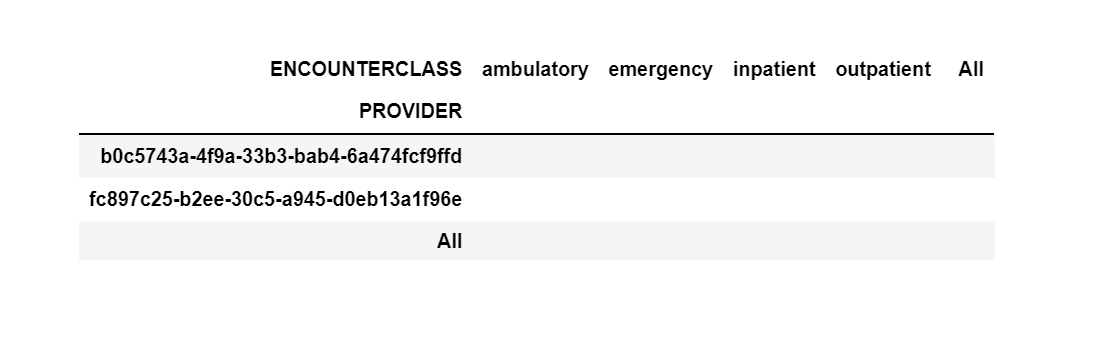

### Encounter Class Frequency Table

- A cross-tabulation table is constructed to summarize the count of encounters per encounter class for each provider.
- This provides the observed frequencies needed for a chi-square test of independence.

In [203]:
df_crosstab = pd.crosstab(filtered_data['PROVIDER'], filtered_data['ENCOUNTERCLASS'], margins=True)
df_crosstab

ENCOUNTERCLASS,ambulatory,emergency,inpatient,outpatient,All
PROVIDER,,,,,
b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,36,49,20,15,120
fc897c25-b2ee-30c5-a945-d0eb13a1f96e,49,36,20,15,120
All,85,85,40,30,240


To improve readability, the cross-tab labels are renamed to clearly indicate provider rows and encounter class columns

In [204]:
# insert your code here:

df_crosstab.index = ['provider_1', 'provider_2', 'col_total']
df_crosstab.columns = ['ambulatory', 'emergency', 'inpatient', 'outpatient', 'row_total']
df_crosstab

,ambulatory,emergency,inpatient,outpatient,row_total
provider_1,36,49,20,15,120
provider_2,49,36,20,15,120
col_total,85,85,40,30,240


### Contingency Table Construction

For hypothesis testing, the contingency table must exclude the row/column totals. 
The resulting 2xk table represents observed counts by provider (rows) and encounter class (columns).

In [205]:
# insert your code here:

contingency_table = df_crosstab.iloc[:-1, :-1]
contingency_table

,ambulatory,emergency,inpatient,outpatient
provider_1,36,49,20,15
provider_2,49,36,20,15


#### Hyptheses (Chi-square test of Independence)
- **Null Hypothesis (H₀):** Encounter class distribution is independent of provider identity  
  (i.e., both providers have the same encounter class proportions).

- **Alternative Hypothesis (H₁):** Encounter class distribution depends on provider identity  
  (i.e., at least one encounter class proportion differs between providers).

Significance level: α = 0.05

### Statistical Test
A chi-square test of independence is performed using `scipy.stats.chi2_contingency` on the contingency table. 
The test evaluates whether the observed differences in encounter class counts are larger than would be expected by chance.

In [206]:
from scipy.stats import chi2_contingency
result = chi2_contingency(contingency_table)
result

Chi2ContingencyResult(statistic=3.976470588235294, pvalue=0.26401611615603204, dof=3, expected_freq=array([[42.5, 42.5, 20. , 15. ],
       [42.5, 42.5, 20. , 15. ]]))

#### Test Result
The p-value from the chi-square test is:
- **p-value:** 0.263

#### Interpretation (95% Confidence Level)

With **p = 0.263** and **α = 0.05**, we fail to reject the null hypothesis.

This indicates **insufficient statistical evidence** to claim that encounter class distributions differ between the two providers. Any observed differences in encounter mix may be attributable to sampling variability rather than systematic variation in practice patterns.

#### Part 2: The goal of this machine learning section is to build a binary classification model that predicts whether a health insurance claim will be "PAID" or "DENIED". The business objective is to reduce missed denied claims, as claims that should be denied but are incorrectly predicted as paid may result in unnecessary claim payouts and financial loss.

In [207]:
encounters = encounters.rename(columns={"ID": "visit_id", "PATIENT": "patient_id", "PROVIDER": "provider_id", "ORGANIZATION": "healthcare_organization_id", "ENCOUNTERCLASS": "visit_type", "TOTAL_CLAIM_COST": "total_visit_claim_cost"})
encounters.isna().sum()

visit_id                      0
patient_id                    0
provider_id                   0
healthcare_organization_id    0
visit_type                    0
total_visit_claim_cost        0
dtype: int64

In [208]:
claims = claims.rename(columns={"ID": "claims_id", "ENCOUNTER": "visit_id", "PATIENT": "patient_id", "PROVIDER": "provider_id", "ORGANIZATION": "healthcare_organization_id", "SERVICE_DATE": "service_date", "CLAIM_AMOUNT": "claim_amount", "STATUS": "claim_status"})
claims.isna().sum()

claims_id                     0
visit_id                      0
patient_id                    0
provider_id                   0
healthcare_organization_id    0
service_date                  0
claim_amount                  0
claim_status                  0
dtype: int64

In [209]:
organizations = organizations.rename(columns={"ID": "healthcare_organization_id", "NAME": "organization_name", "CITY": "organization_city", "STATE": "organization_state"})
organizations.isna().sum()

healthcare_organization_id    0
organization_name             0
organization_city             0
organization_state            0
dtype: int64

In [210]:
patients = patients.rename(columns={"ID": "patients_id", "NAME": "patient_name", "GENDER": "patient_gender", "BIRTHDATE": "patient_birthdate", "CITY": "patient_city", "STATE": "patient_state"})
patients.isna().sum()

patients_id          0
patient_name         0
patient_gender       0
patient_birthdate    0
patient_city         0
patient_state        0
dtype: int64

In [211]:
providers = providers.rename(columns={"ID": "providers_id", "NAME": "providers_name", "SPECIALITY": "providers_speciality", "GENDER": "providers_gender", "ORGANIZATION": "healthcare_organization_id"})
providers.isna().sum()

providers_id                  0
providers_name                0
providers_speciality          0
providers_gender              0
healthcare_organization_id    0
dtype: int64

#### Merge both encounters and claims data

In [212]:
result = pd.merge(encounters, claims, on='visit_id', how='left')
result

,visit_id,patient_id_x,provider_id_x,healthcare_organization_id_x,visit_type,total_visit_claim_cost,claims_id,patient_id_y,provider_id_y,healthcare_organization_id_y,service_date,claim_amount,claim_status
0,42db7c89-155a-4822-a83b-108297566c6d,216ef7c6-5d75-4ed2-9e88-7590f5a62e8d,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,inpatient,666.17,6574d9d1-2f4d-48c5-b3f0-816fd12e185b,216ef7c6-5d75-4ed2-9e88-7590f5a62e8d,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,2025-08-23,647.00,PAID
1,4582737d-9c66-4231-8744-25e9a37e8f32,2f520255-a75c-4b2d-b859-635c1e7afe0b,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,outpatient,461.31,e9065bea-2b5b-4ee4-aca7-f4bac4175ded,2f520255-a75c-4b2d-b859-635c1e7afe0b,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,2025-01-28,486.53,DENIED
2,21340ce9-082a-4f62-a53a-2533c43d355b,f3c98a41-b8d8-498b-b2e3-231cd8ae8916,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,508.69,65e58e8c-e2c6-4d3e-ba19-6b14e777608d,f3c98a41-b8d8-498b-b2e3-231cd8ae8916,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,2025-04-13,520.54,PAID
3,11c9005f-d83b-4cc5-be3b-0134603f1efb,16f9eb9f-f276-404e-a785-ef64af0b29e8,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,544.28,b493e288-1cb7-4865-8efb-502d9385031c,16f9eb9f-f276-404e-a785-ef64af0b29e8,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,2025-07-21,577.86,PAID
4,62c82b0c-7c53-4501-b99b-15f96d6df6f1,66062c99-6bf7-4226-92e2-726e799e2588,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,ambulatory,430.62,8c2cbead-2987-46f9-805d-7519a9e455da,66062c99-6bf7-4226-92e2-726e799e2588,bb49afa2-3d8a-306c-a06e-a1715dd71af8,226098a2-6a40-3588-b5bb-db56c3a30a04,2024-09-14,394.25,DENIED
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5095,3e4d48b8-e022-4b5b-9fa3-0f92c87e7138,ca3ae481-0db6-4f26-846b-71e7a0a2e6d2,0df1d27c-9bcc-4030-b7ea-f44284e5a379,d88dcaf5-f283-4158-a4d5-3df46261794e,inpatient,485.20,93449889-8437-490f-b882-6018b07bf1f3,ca3ae481-0db6-4f26-846b-71e7a0a2e6d2,0df1d27c-9bcc-4030-b7ea-f44284e5a379,d88dcaf5-f283-4158-a4d5-3df46261794e,2024-06-29,516.09,ADJUSTED
5096,3dc27814-13c3-4040-97a2-566db22122ef,5983ddfc-4740-456e-ae68-6f6972103ec8,69a805c6-9d0a-496a-b451-1ca8b89cb225,981a09bc-b549-458f-814c-a2ade0adf60f,ambulatory,513.59,0741ab72-6781-4eb1-ab38-279502e94832,5983ddfc-4740-456e-ae68-6f6972103ec8,69a805c6-9d0a-496a-b451-1ca8b89cb225,981a09bc-b549-458f-814c-a2ade0adf60f,2025-06-21,461.93,DENIED
5097,b764d2dd-b013-4d5b-9d84-05baa8af70a5,8e181b8f-1abb-410d-ac92-80a3414bfbe6,b410c143-dba9-429e-acbe-2b921af22c3e,e5afe40c-91ef-42d7-a25c-41ef5f41663a,inpatient,569.59,9bb51524-47a6-413a-bfb9-d28a5b8aba9b,8e181b8f-1abb-410d-ac92-80a3414bfbe6,b410c143-dba9-429e-acbe-2b921af22c3e,e5afe40c-91ef-42d7-a25c-41ef5f41663a,2024-10-01,565.70,PAID
5098,ccc2c153-9644-4e39-bc59-54425b0800ef,4b5533b5-1a7e-417d-a8c0-63aa77bf4d0f,ffea9728-5110-434a-8608-6c5bc8529450,3a00bb32-3f67-44dd-86c2-aa8cb715438b,ambulatory,323.56,2c3ee75b-1649-4cda-918b-e7121f341df7,4b5533b5-1a7e-417d-a8c0-63aa77bf4d0f,ffea9728-5110-434a-8608-6c5bc8529450,3a00bb32-3f67-44dd-86c2-aa8cb715438b,2025-11-12,310.35,DENIED


#### Join patients tables together with encounters and claims data

In [213]:
result_ = result.merge(patients, left_on='patient_id_y', right_on='patients_id', how='left')

#### Converting patient birthdate into age into numeric numbers for preprocessing

In [214]:
result_['patient_birthdate'] = pd.to_datetime(result_['patient_birthdate'], errors='coerce')
result_['patient_age'] = (pd.Timestamp.today() - result_['patient_birthdate']).dt.days // 365

#### Filtering out claim status for both paid and denied claims and remove any assumptions for claims that is being adjusted or pending

In [215]:
result_ = result_[(result_['claim_status'] == 'PAID') | (result_['claim_status'] == 'DENIED')] 

#### Unique Value Check

In [216]:
result_.nunique()

visit_id                        2537
patient_id_x                    2027
provider_id_x                   1891
healthcare_organization_id_x    1602
visit_type                         4
total_visit_claim_cost          2456
claims_id                       2537
patient_id_y                    2027
provider_id_y                   1891
healthcare_organization_id_y    1602
service_date                     709
claim_amount                    2443
claim_status                       2
patients_id                     2027
patient_name                    2027
patient_gender                     2
patient_birthdate               1962
patient_city                       6
patient_state                      4
patient_age                       72
dtype: int64

In [217]:
X = result_[['visit_type', 'total_visit_claim_cost', 'claim_amount', 'patient_gender', 'patient_age']]
y = result_['claim_status']

In [218]:
category = ['visit_type', 'patient_gender']
numeric = ['total_visit_claim_cost', 'claim_amount', 'patient_age']

#### Checking on class imbalance

In [219]:
(result_['claim_status'].value_counts(normalize=True) * 100.0).round(2)

claim_status
PAID      51.32
DENIED    48.68
Name: proportion, dtype: float64

#### One hot encoding

In [220]:
preprocess = ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), category), ('num', 'passthrough', numeric)])

In [221]:
model_rf = Pipeline([('preprocess', preprocess), ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))])
model_gb = Pipeline([('preprocess', preprocess), ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))])

#### The dataset is split into training, validation and test  sets using a 60/20/20 split. 

- Training data is used to fit the models.
- Validation data is used to compare models and tune the decision threshold
- Test data is reserved for final model evaluation

Stratified splitting is used to preserve the proportion of PAID and DENIED claims across all sets

In [222]:
#60% train, 40% temp

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

#Split temp into 20% val and 20% test

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [223]:
print(len(X_train) / len(X))
print(len(X_val) / len(X))
print(len(X_test) / len(X))

0.5999211667323611
0.1998423334647221
0.20023649980291683


#### Using train data to do model fitting into Random Forest Classifier and validation data to evaluate the model performance

In [224]:
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_val)

print(classification_report(y_val, y_pred_rf))

              precision    recall  f1-score   support

      DENIED       0.52      0.48      0.50       247
        PAID       0.54      0.57      0.55       260

    accuracy                           0.53       507
   macro avg       0.53      0.53      0.52       507
weighted avg       0.53      0.53      0.53       507



#### Using train data to do model fitting into Gradient Boosting and valdiation data to evaluate the model performance

In [225]:
model_gb.fit(X_train, y_train)

y_pred_gb = model_gb.predict(X_val)

print(classification_report(y_val, y_pred_gb))

              precision    recall  f1-score   support

      DENIED       0.52      0.41      0.46       247
        PAID       0.53      0.63      0.58       260

    accuracy                           0.53       507
   macro avg       0.53      0.52      0.52       507
weighted avg       0.53      0.53      0.52       507



#### Based on the confusion matrix for random forest, we saw that 129 missing denied claims out of 247 total denied claims which may have a huge impact because close to 50% of the denied claims are not predicted as denied claims thus allowing the system to pay to the policyholders.

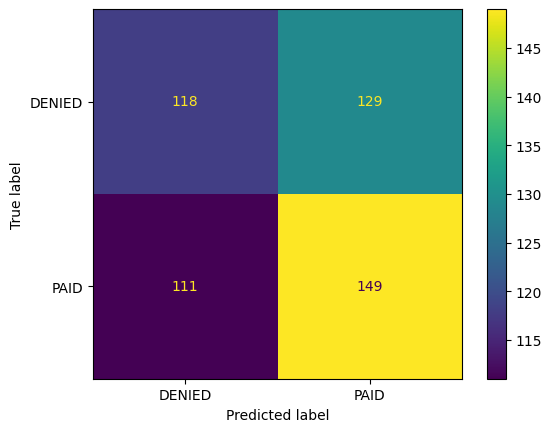

In [226]:
cm_rf = confusion_matrix(y_val, y_pred_rf, labels=['DENIED', 'PAID'])
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['DENIED', 'PAID'])

disp_rf.plot()
plt.show()

#### Based on the confusion matrix, gradient boosting has a significantly higher of 145 missed denied claims than random forest. This creates a significant higher risk than random forest because of additional 16 more claims that is being passed while denied. 

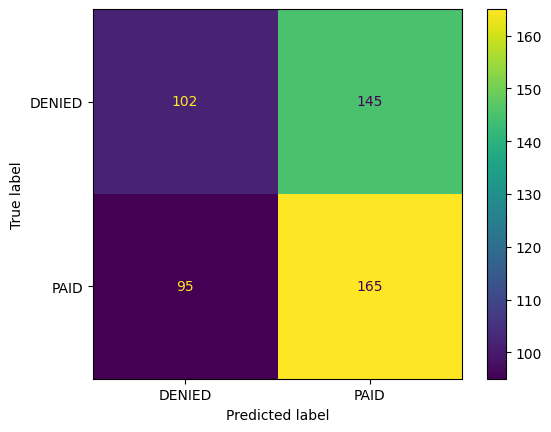

In [227]:
cm_gb = confusion_matrix(y_val, y_pred_gb, labels=['DENIED', 'PAID'])
disp_gb = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=['DENIED', 'PAID'])

disp_gb.plot()
plt.show()

#### Threshold tuning was performed on the validation set to improve recall for the DENIED class. Since the business risk is mainly related to missed denied claims, the threshold was adjusted below the default 0.5 to classify more claims as DENIED. A threshold of 0.40 was selected because it improved recall for DENIED claims compared with the default threshold, although this may reduce precision and increase false positives. 

In [ ]:
denied_prob_gb = model_gb.predict_proba(X_val)[:, 0]
denied_prob_rf = model_rf.predict_proba(X_val)[:, 0]

thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4]

for threshold_gb in thresholds:
    y_pred_tuned_gb = np.where(denied_prob_gb >= threshold_gb, 'DENIED', 'PAID')

    print(f"\nThreshold_gb: {threshold_gb}")
    print(classification_report(y_val, y_pred_tuned_gb))

for threshold_rf in thresholds:
    y_pred_tuned_rf = np.where(denied_prob_rf >= threshold_rf, 'DENIED', 'PAID')

    print(f"\nThreshold_rf: {threshold_rf}")
    print(classification_report(y_val, y_pred_tuned_rf))




Threshold_gb: 0.1
              precision    recall  f1-score   support

      DENIED       0.49      1.00      0.66       247
        PAID       0.00      0.00      0.00       260

    accuracy                           0.49       507
   macro avg       0.24      0.50      0.33       507
weighted avg       0.24      0.49      0.32       507


Threshold_gb: 0.15
              precision    recall  f1-score   support

      DENIED       0.49      1.00      0.66       247
        PAID       0.67      0.01      0.02       260

    accuracy                           0.49       507
   macro avg       0.58      0.50      0.34       507
weighted avg       0.58      0.49      0.33       507


Threshold_gb: 0.2
              precision    recall  f1-score   support

      DENIED       0.49      0.98      0.65       247
        PAID       0.44      0.02      0.03       260

    accuracy                           0.49       507
   macro avg       0.47      0.50      0.34       507
weighted avg    

/Users/chityan/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/chityan/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/chityan/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r

In [229]:
print(f"\nThreshold_gb: {threshold_gb}")
print(f"\nThreshold_rf: {threshold_rf}")


Threshold_gb: 0.4

Threshold_rf: 0.4


#### After threshold tuning at 0.4, recall for the DENIED class improved, especially for Gradient Boosting. However, this came at the cost of lower precision and overall accuracy. This means the model is better at catching denied claims, but it also creates more false alarms.

In [230]:
denied_prob_gb_test = model_gb.predict_proba(X_test)[:, 0]
denied_prob_rf_test = model_rf.predict_proba(X_test)[:, 0]

threshold_gb_rf = [0.4]

for threshold_gb_test in threshold_gb_rf:
    y_pred_test_gb = np.where(denied_prob_gb_test >= threshold_gb_test, 'DENIED', 'PAID')

for threshold_rf_test in threshold_gb_rf:
    y_pred_test_rf = np.where(denied_prob_rf_test >= threshold_rf_test, 'DENIED', 'PAID')


print(f"\nThreshold_gb: {threshold_gb}")
print(classification_report(y_test, y_pred_test_gb))
print(f"\nThreshold_rf: {threshold_rf}")
print(classification_report(y_test, y_pred_test_rf))


Threshold_gb: 0.4
              precision    recall  f1-score   support

      DENIED       0.48      0.84      0.61       247
        PAID       0.46      0.13      0.20       261

    accuracy                           0.47       508
   macro avg       0.47      0.48      0.41       508
weighted avg       0.47      0.47      0.40       508


Threshold_rf: 0.4
              precision    recall  f1-score   support

      DENIED       0.50      0.67      0.57       247
        PAID       0.54      0.37      0.44       261

    accuracy                           0.52       508
   macro avg       0.52      0.52      0.51       508
weighted avg       0.52      0.52      0.50       508



#### For random forest classification, total visit claim cost and claim amount used the most to predict the claim status. This helps to explain whether claim amount, visit type, patient age or patient gender had stronger influence on the model's predictions. 

In [231]:
feature_names_rf = model_rf.named_steps['preprocess'].get_feature_names_out()
importances_rf = model_rf.named_steps['classifier'].feature_importances_

feature_importance_rf = pd.DataFrame({
    'feature': feature_names_rf,
    'importance': importances_rf
}).sort_values(by='importance', ascending=False)

feature_importance_rf

,feature,importance
7,num__claim_amount,0.323537
6,num__total_visit_claim_cost,0.321516
8,num__patient_age,0.277706
3,cat__visit_type_outpatient,0.014440
2,cat__visit_type_inpatient,0.014248
0,cat__visit_type_ambulatory,0.014158
1,cat__visit_type_emergency,0.013233
4,cat__patient_gender_F,0.010907
5,cat__patient_gender_M,0.010254


#### For gradient boosting, total visit claim cost and claim amount used the most to predict the claim status. This is very much similar to the feature importance shown in random forest classifier which total visit claim cost and claim amount had a higher influence on the model's predictions.

In [232]:
feature_names_gb = model_gb.named_steps['preprocess'].get_feature_names_out()
importances_gb = model_gb.named_steps['classifier'].feature_importances_

feature_importance_gb = pd.DataFrame({
    'feature': feature_names_gb,
    'importance': importances_gb
}).sort_values(by='importance', ascending=False)

feature_importance_gb

,feature,importance
6,num__total_visit_claim_cost,0.347814
7,num__claim_amount,0.347271
8,num__patient_age,0.223991
1,cat__visit_type_emergency,0.031214
3,cat__visit_type_outpatient,0.014617
2,cat__visit_type_inpatient,0.013064
4,cat__patient_gender_F,0.008830
5,cat__patient_gender_M,0.008178
0,cat__visit_type_ambulatory,0.005022
